<a href="https://colab.research.google.com/github/umetaisa2004-commits/content-ops-starter/blob/main/20260909PIcontrol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
class PIController:
    # 実運用を想定したPIコントローラー

    def __init__(self, Kp, Ki, min_out, max_out):
        self.Kp = Kp  # 比例ゲイン (P制御の強さ)
        self.Ki = Ki  # 積分ゲイン (I制御の強さ)
        self.min_out = min_out  # ポンプ出力下限 (例: 0%)
        self.max_out = max_out  # ポンプ出力上限 (例: 100%)
        self.integral = 0.0  # 誤差の累積値

    def compute(self, setpoint, measured_value, dt):
        # 1. 偏差(エラー)の計算
        error = setpoint - measured_value

        # 2. 積分項の更新 (dt: サンプリング周期を乗算)
        self.integral += error * dt

        # 3. ★アンチワインドアップ処理(重要)★
        # ポンプ能力上限以上の要求が続いた際、積分項が無限に溜まるのを防ぐ
        i_term = self.Ki * self.integral
        if i_term > self.max_out:
            i_term = self.max_out
            self.integral = self.max_out / self.Ki
        elif i_term < self.min_out:
            i_term = self.min_out
            self.integral = self.min_out / self.Ki

        # 4. 比例項の計算
        p_term = self.Kp * error

        # 5. 操作量(凝集剤注入率)の決定
        output = p_term + i_term

        # ポンプの出力下限・上限でクリッピングして返す
        return max(self.min_out, min(self.max_out, output))

In [ ]:
import time
import random

# ----- さきほどのPIコントローラークラス -----
class PIController:
    def __init__(self, Kp, Ki, min_out, max_out):
        self.Kp = Kp
        self.Ki = Ki
        self.min_out = min_out
        self.max_out = max_out
        self.integral = 0.0

    def compute(self, setpoint, measured_value, dt):
        error = setpoint - measured_value
        self.integral += error * dt

        i_term = self.Ki * self.integral
        if i_term > self.max_out:
            i_term = self.max_out
            self.integral = self.max_out / self.Ki
        elif i_term < self.min_out:
            i_term = self.min_out
            self.integral = self.min_out / self.Ki

        p_term = self.Kp * error
        output = p_term + i_term
        return max(self.min_out, min(self.max_out, output))


# ----- 現場の機器の代わりをするダミー関数 -----

def analyze_image_for_speed():
    """① 画像分析の代わり：カメラから現在のフロック移動速度を取得したと仮定する"""
    # 実際はここでOpenCVなどの画像処理が動きますが、
    # 今回はテストとして -5.0 〜 2.0 の適当な速度(乱数)を返します
    simulated_speed = random.uniform(-5.0, 2.0)
    return simulated_speed

def inject_coagulant(rate):
    """③ ポンプ操作の代わり：計算された注入率をポンプに指示する"""
    # 実際はここでPLC(制御機器)へ電気信号を送りますが、今回は画面に表示するだけです
    print(f" └─> [ポンプ操作] 凝集剤の注入率を {rate:.1f}% に設定しました")


# ----- メインの連続ループ処理 -----

def main():
    print("=== 水処理 自動制御システムを起動します ===")

    # コントローラーの設定 (P=1.5, I=0.4, 出力0%〜100%)
    controller = PIController(Kp=1.5, Ki=0.4, min_out=0, max_out=100)
    target_speed = 0.0  # 目標値は 0 µm/s (荷電中和状態)
    dt = 1.0            # 1秒ごとにループを回す

    try:
        # ここから無限ループ（強制終了するまで永遠に繰り返す）
        while True:
            print("\n--- 処理サイクル開始 ---")

            # ① 測定：画像分析から現在の移動速度を取得
            current_speed = analyze_image_for_speed()
            print(f"① [画像分析] 現在の移動速度: {current_speed:.2f} µm/s")

            # ② 計算：PI制御で次に入れるべき凝集剤の量を計算
            injection_rate = controller.compute(target_speed, current_speed, dt)
            print(f"② [PI制御]  目標({target_speed})とのズレから注入率 {injection_rate:.1f}% を算出")

            # ③ 操作：計算した注入率を現場のポンプに反映
            inject_coagulant(injection_rate)

            # 1秒間待機する（dt = 1.0）
            time.sleep(dt)

    except KeyboardInterrupt:
        # ユーザーが停止ボタン(または Ctrl+C)を押した時の処理
        print("\n=== システムを安全に停止しました ===")

# プログラムの実行開始
if __name__ == "__main__":
    main()

=== 水処理 自動制御システムを起動します ===

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: -2.74 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 5.2% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 5.2% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: -1.70 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 4.3% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 4.3% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: 0.77 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 0.3% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 0.3% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: -3.47 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 8.1% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 8.1% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: 1.17 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 0.6% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 0.6% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: 0.13 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 2.1% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 2.1% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: 0.24 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 1.9% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 1.9% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速度: -3.32 µm/s
② [PI制御]  目標(0.0)とのズレから注入率 8.5% を算出
 └─> [ポンプ操作] 凝集剤の注入率を 8.5% に設定しました

--- 処理サイクル開始 ---
① [画像分析] 現在の移動速

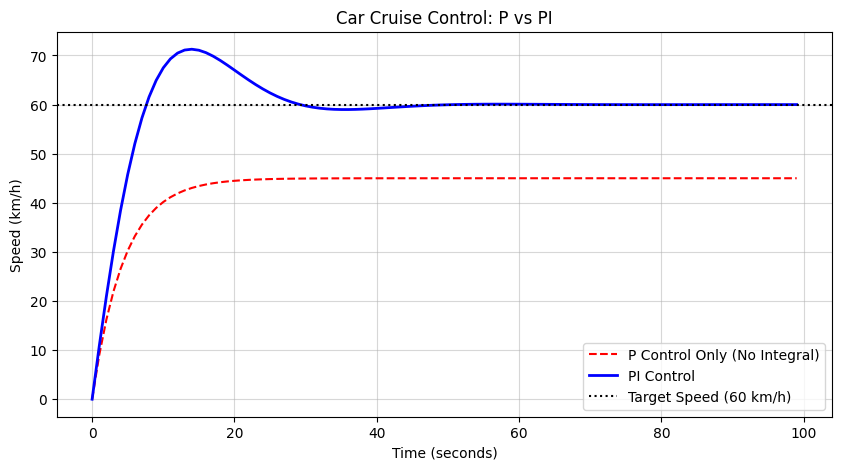

In [ ]:
import matplotlib.pyplot as plt

# ==========================================
# 1. シミュレーションの設定
# ==========================================
time_steps = 100       # 100秒間シミュレーションする
target_speed = 60.0    # 目標速度（60 km/h）
dt = 1.0               # 1秒ごとに計算

# 記録用のリスト（グラフ描画用）
history_p_only = []
history_pi = []

# ==========================================
# 2. P制御（比例のみ）のシミュレーション
# ==========================================
current_speed = 0.0
Kp = 1.5  # P制御の強さ

for t in range(time_steps):
    history_p_only.append(current_speed)

    # ① ズレの計算
    error = target_speed - current_speed

    # ② 操作量の計算（Pのみ）
    power = Kp * error

    # ③ 車の走行モデル（アクセルを踏むと加速し、空気抵抗で少し減速する）
    current_speed += (power * 0.1 - current_speed * 0.05) * dt


# ==========================================
# 3. PI制御のシミュレーション
# ==========================================
current_speed = 0.0
Kp = 1.5  # P制御の強さ
Ki = 0.3  # I制御の強さ
integral = 0.0  # 過去のズレの蓄積

for t in range(time_steps):
    history_pi.append(current_speed)

    # ① ズレの計算
    error = target_speed - current_speed

    # ② 過去のズレを蓄積（積分）
    integral += error * dt

    # ③ 操作量の計算（Pの力 ＋ Iの力）
    p_term = Kp * error
    i_term = Ki * integral
    power = p_term + i_term

    # ④ 車の走行モデル
    current_speed += (power * 0.1 - current_speed * 0.05) * dt

# ==========================================
# 4. グラフの描画
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(history_p_only, label='P Control Only (No Integral)', linestyle='--', color='red')
plt.plot(history_pi, label='PI Control', linewidth=2, color='blue')
plt.axhline(target_speed, color='black', linestyle=':', label='Target Speed (60 km/h)')

plt.xlabel('Time (seconds)')
plt.ylabel('Speed (km/h)')
plt.title('Car Cruise Control: P vs PI')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.5)
plt.show()